# K-Nearest Neighbors (KNN) Classification & Regression

KNN is characterized by two fundamental properties:

* **Non-Parametric:** It makes no explicit assumptions about the functional form or underlying probability distribution of the data (e.g., it does not assume linearity or normality).
* **Lazy Learning (Instance-Based):** KNN does not learn a discriminative function during a distinct training phase. Instead, it memorizes the entire dataset and defers all computations until a prediction query is made.


Given a query point $x_{\text{test}}$, KNN identifies the $K$ training samples that are closest in distance to $x_{\text{test}}$ and aggregates their target values to make a prediction.

---

## Distance Metrics & Feature Scaling

### Common Distance Metrics

For two data points $p = (p_1, p_2, \dots, p_d)$ and $q = (q_1, q_2, \dots, q_d)$ in $d$-dimensional feature space:

**Euclidean Distance ($L_2$ Norm):**

$$d(p, q) = \sqrt{\sum_{j=1}^{d} (p_j - q_j)^2}$$


**Manhattan Distance ($L_1$ Norm):**

$$d(p, q) = \sum_{j=1}^{d} \vert{}p_j - q_j\vert{}$$


Features must be normalized or standardized prior to applying KNN:

* **Standardization ($Z$-score scaling):**

$$x_{\text{scaled}} = \frac{x - \mu}{\sigma}$$


* **Min-Max Normalization:**

$$x_{\text{scaled}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$


---

## KNN for Regression

In a regression setting, the target variable $y$ is continuous. Instead of voting, KNN computes the average or weighted average of the continuous values of the $K$ nearest neighbors.

### Mathematical Formulation

* **Unweighted Average:**

$$\hat{y} = \frac{1}{K} \sum_{i \in N_K(x_{\text{test}})} y_i$$


* **Distance-Weighted Average:**

$$\hat{y} = \frac{\sum_{i \in N_K(x_{\text{test}})} w_i y_i}{\sum_{i \in N_K(x_{\text{test}})} w_i}, \quad \text{where } w_i = \frac{1}{d(x_{\text{test}}, x_i)}$$



### Numerical Example (KNN Regression)

Using the same feature coordinates, suppose the target values represent continuous house price indexes:

| Training Point | $x_1$ | $x_2$ | Target Value ($y$) | Distance to $Q(3,3)$ |
| --- | --- | --- | --- | --- |
| **A** | 1 | 2 | 100 | $2.24$ |
| **B** | 2 | 3 | 120 | $1.00$ |
| **C** | 5 | 4 | 240 | $2.24$ |
| **D** | 6 | 5 | 300 | $3.61$ |

For query $Q(3, 3)$ with $K = 3$:

1. The $3$ nearest neighbors are **B** ($y=120$), **A** ($y=100$), and **C** ($y=240$).
2. **Unweighted Prediction:**

$$\hat{y} = \frac{120 + 100 + 240}{3} = \frac{460}{3} \approx 153.33$$



---

## Deciding the Choice of $K$

The choice of hyperparameter $K$ determines the balance between bias and variance in the model.

### The Bias-Variance Tradeoff in KNN

| Value of $K$ | Model Complexity | Decision Boundary | Risk |
| --- | --- | --- | --- |
| **Small $K$** (e.g., $K=1$) | Flexible, High Complexity | Highly jagged, fitting individual noise points | **Low Bias, High Variance** (Overfitting) |
| **Large $K$** (e.g., $K=N$) | Rigid, Low Complexity | Smooth, predicting global average/majority | **High Bias, Low Variance** (Underfitting) |

```
High Variance (Overfitting) <--------------------------> High Bias (Underfitting)
         K = 1                 Optimal K                     K = N

```

### Strategies for Selecting $K$

1. **Odd Numbers for Binary Classification:** Choose odd values for $K$ (e.g., 3, 5, 7) to avoid tie votes when using equal weights.
2. **Rule of Thumb Initial Bound:** Set $K \approx \sqrt{N}$, where $N$ is the total number of samples in the dataset.
3. **Cross-Validation Tuning:** Perform $K$-Fold Cross-Validation across a grid of candidate $K$ values (e.g., $K \in \{1, 3, 5, \dots, 30\}$) and plot validation error against $K$. Choose the value of $K$ that minimizes validation error.

---

## Computational Complexity & Limitations

* **Time Complexity:**
* Training: $O(1)$ (no explicitly computed parameters).
* Inference/Prediction: $O(N \cdot d)$ per test sample, where $N$ is training samples and $d$ is features. Query times become slow with large datasets.


* **Curse of Dimensionality:** In high-dimensional spaces ($d \gg 100$), distance metrics lose discriminative power because the distance between any two points converges to a constant value. Dimensionality reduction (e.g., PCA) should be performed prior to KNN in high-dimensional domains.

---

---

### Demo: KNN Regression

This example demonstrates continuous function approximation using KNN Regression with different values of $K$.

In [ ]:
import numpy as np
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# 1. Generate Synthetic Regression Dataset
np.random.seed(42)
X = np.sort(5 * np.random.rand(200, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, X.shape[0])

# Split into Train and Test sets
split_idx = 160
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# 2. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Compare Regression Performance for Different K
k_values = [1, 5, 20]

for k in k_values:
    # Initialize and fit KNN Regressor
    regressor = KNeighborsRegressor(n_neighbors=k, weights='uniform')
    regressor.fit(X_train_scaled, y_train)

    # Predict on test data
    y_pred = regressor.predict(X_test_scaled)

    # Calculate performance metrics
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"K = {k:2d} | Test MSE: {mse:.4f} | R^2 Score: {r2:.4f}")

K =  1 | Test MSE: 0.0927 | R^2 Score: -4.9502
K =  5 | Test MSE: 0.0685 | R^2 Score: -3.3944
K = 20 | Test MSE: 0.1690 | R^2 Score: -9.8484


## KNN for Classification

In a classification setting, KNN assigns a categorical class label to a query point based on the majority vote of its $K$ nearest neighbors.

### Algorithm

1. Select the parameter $K$ and a distance metric (e.g., Euclidean).
2. Calculate the distance between the query point $x_{\text{test}}$ and all training instances.
3. Sort distances in ascending order and select the top $K$ nearest training points $N_K(x_{\text{test}})$.
4. **Majority Vote:** Assign the class label $y_{\text{pred}}$ that appears most frequently among the $K$ neighbors:

$$y_{\text{pred}} = \arg\max_{c} \sum_{i \in N_K(x_{\text{test}})} \mathbb{I}(y_i = c)$$



where $\mathbb{I}(\cdot)$ is an indicator function returning $1$ if true, and $0$ otherwise.

### Distance-Weighted Classification

Instead of giving equal weight to all $K$ neighbors, closer neighbors can be given higher influence using inverse distance weights:


$$w_i = \frac{1}{d(x_{\text{test}}, x_i)}$$

### Numerical Example (KNN Classification)

Consider a 2D dataset with two classes ($0$ and $1$). We want to classify a query point $Q = (3, 3)$ using $K = 3$ and Euclidean distance.

| Training Point | $x_1$ | $x_2$ | Class ($y$) |
| --- | --- | --- | --- |
| **A** | 1 | 2 | 0 |
| **B** | 2 | 3 | 0 |
| **C** | 5 | 4 | 1 |
| **D** | 6 | 5 | 1 |

1. **Calculate Euclidean distances from $Q(3, 3)$:**
* $d(Q, A) = \sqrt{(3-1)^2 + (3-2)^2} = \sqrt{4 + 1} = \sqrt{5} \approx 2.24$
* $d(Q, B) = \sqrt{(3-2)^2 + (3-3)^2} = \sqrt{1 + 0} = \sqrt{1} = 1.00$
* $d(Q, C) = \sqrt{(3-5)^2 + (3-4)^2} = \sqrt{4 + 1} = \sqrt{5} \approx 2.24$
* $d(Q, D) = \sqrt{(3-6)^2 + (3-5)^2} = \sqrt{9 + 4} = \sqrt{13} \approx 3.61$


2. **Select top $K=3$ nearest neighbors:**
* 1st closest: **B** ($d = 1.00$, Class 0)
* 2nd closest: **A** ($d \approx 2.24$, Class 0)
* 3rd closest: **C** ($d \approx 2.24$, Class 1)


3. **Majority Vote:**
* Class 0: 2 votes (from B and A)
* Class 1: 1 vote (from C)
* **Predicted Class:** **0**



---


## Metrics:
* False positives, False Negatives, Confusion Matrix
* Precision, Recall
* ROC Curve


1. Precision

• What it measures: Of all the instances your model predicted as positive, how many were actually positive?
• Formula: $$\text{Precision} = \frac{\text{True Positives (TP)}}{\text{True Positives (TP)} + \text{False Positives (FP)}}$$
• Key takeaway: High precision means fewer false alarms (type I errors). Use it when the cost of a false positive is high (e.g., spam detection or financial fraud, good email getting tagged as spam).

2. Recall, F1-Score, and Support

• Recall: Measures the proportion of actual positive instances successfully identified by the model. Critical when **missing positive cases is costly**  (eg. secure entry - letting in a burglar).
Formula: $$\text{Recall} = \frac{\text{True Positives (TP)}}{\text{True Positives (TP)} + \text{False Negatives (FP)}}$$

• F1-Score: The harmonic mean of precision and recall that balances both metrics. Additional details are available at Scikit-Learn Metrics.
• Support: The number of true occurrences for each class in the data, providing context for sample sizes

### Demo: KNN Classification & Hyperparameter Selection

The following script demonstrates scaling, model training, and searching for the optimal $K$ value using Cross-Validation.

Optimal K selected by CV: 9
Test Accuracy: 0.9500

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.94      0.95        51
           1       0.94      0.96      0.95        49

    accuracy                           0.95       100
   macro avg       0.95      0.95      0.95       100
weighted avg       0.95      0.95      0.95       100


 Confusion Matrix:
 [[48  3]
 [ 2 47]]


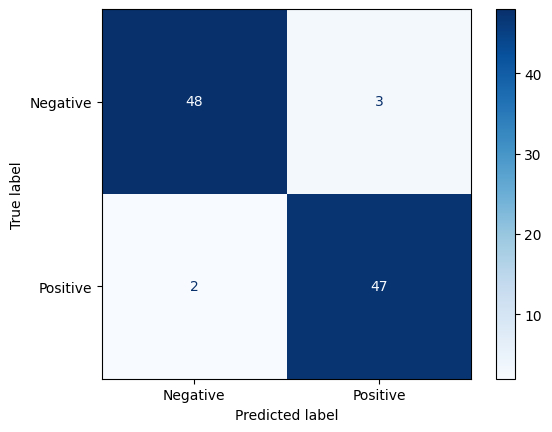

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Generate Synthetic Data
X, y = make_classification(
    n_samples=500,
    n_features=4,
    n_informative=3,
    n_redundant=1,
    random_state=42
)

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Feature Scaling (Crucial for KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Hyperparameter Selection: Tuning K using Cross-Validation
k_candidates = range(1, 31, 2)  # Odd numbers from 1 to 29
cv_scores = []

for k in k_candidates:
    knn = KNeighborsClassifier(n_neighbors=k)
    # 5-Fold Cross Validation
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

# Find optimal K
optimal_k = k_candidates[np.argmax(cv_scores)]
print(f"Optimal K selected by CV: {optimal_k}")

# 5. Retrain Final Model on Scaled Training Data
final_clf = KNeighborsClassifier(n_neighbors=optimal_k)
final_clf.fit(X_train_scaled, y_train)

# 6. Evaluate on Test Set
y_pred = final_clf.predict(X_test_scaled)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("\n Confusion Matrix:\n", cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Blues)

plt.show()

### Receiver Operating Characteristic (ROC)

An ROC curve evaluates the diagnostic ability of a binary classifier across all possible classification probability thresholds $\tau \in [0, 1]$.

An instance is predicted as positive ($\hat{y} = 1$) if $P(y=1 \mid x) \ge \tau$.


The ROC curve plots **True Positive Rate (TPR)** on the $y$-axis against **False Positive Rate (FPR)** on the $x$-axis:

* **True Positive Rate (Sensitivity / Recall):**

$$\text{TPR} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$


* **False Positive Rate ($1 - \text{Specificity}$):**

$$\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$



# Area Under the Curve (AUC)

* **$\text{AUC} = 1.0$:** Perfect classifier (complete separation of positive and negative classes).
* **$\text{AUC} = 0.5$:** Random guessing performance (diagonal baseline).
* **$\text{AUC} < 0.5$:** Predicts worse than chance (implies class labels are inverted).

---

## Example

Consider a test set of $N = 8$ instances evaluated using a $K=5$ KNN model.

| Sample ID | True Class ($y$) | Neighbor Counts (Class 1 / $K=5$) | Predicted Probability $P(y=1 \mid x)$ |
| --- | --- | --- | --- |
| **S1** | 1 | 5 / 5 | 1.0 |
| **S2** | 1 | 4 / 5 | 0.8 |
| **S3** | 0 | 4 / 5 | 0.8 |
| **S4** | 1 | 3 / 5 | 0.6 |
| **S5** | 0 | 2 / 5 | 0.4 |
| **S6** | 1 | 2 / 5 | 0.4 |
| **S7** | 0 | 1 / 5 | 0.2 |
| **S8** | 0 | 0 / 5 | 0.0 |

* **Total Positives ($P = \text{TP} + \text{FN}$):** 4 (Samples 1, 2, 4, 6)
* **Total Negatives ($N = \text{FP} + \text{TN}$):** 4 (Samples 3, 5, 7, 8)

# Sweeping the Threshold ($\tau$)

We vary $\tau$ from $> 1.0$ down to $0.0$ to build the ROC coordinates $(\text{FPR}, \text{TPR})$:

| Threshold ($\tau$) | Predicted Positives ($P(y=1) \ge \tau$) | TP | FP | TN | FN | $\text{TPR} = \frac{\text{TP}}{4}$ | $\text{FPR} = \frac{\text{FP}}{4}$ | Point |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| $> 1.0$ | None | 0 | 0 | 4 | 4 | $0/4 = 0.00$ | $0/4 = 0.00$ | **(0.00, 0.00)** |
| $\le 1.0$ | S1 | 1 | 0 | 4 | 3 | $1/4 = 0.25$ | $0/4 = 0.00$ | **(0.00, 0.25)** |
| $\le 0.8$ | S1, S2, S3 | 2 | 1 | 3 | 2 | $2/4 = 0.50$ | $1/4 = 0.25$ | **(0.25, 0.50)** |
| $\le 0.6$ | S1, S2, S3, S4 | 3 | 1 | 3 | 1 | $3/4 = 0.75$ | $1/4 = 0.25$ | **(0.25, 0.75)** |
| $\le 0.4$ | S1, S2, S3, S4, S5, S6 | 4 | 2 | 2 | 0 | $4/4 = 1.00$ | $2/4 = 0.50$ | **(0.50, 1.00)** |
| $\le 0.2$ | S1, S2, S3, S4, S5, S6, S7 | 4 | 3 | 1 | 0 | $4/4 = 1.00$ | $3/4 = 0.75$ | **(0.75, 1.00)** |
| $\le 0.0$ | All samples | 4 | 4 | 0 | 0 | $4/4 = 1.00$ | $4/4 = 1.00$ | **(1.00, 1.00)** |

Plotting these coordinates and joining them with line segments creates the step-like ROC curve typical of KNN models.

---

ROC-AUC Score for K=15: 0.9692


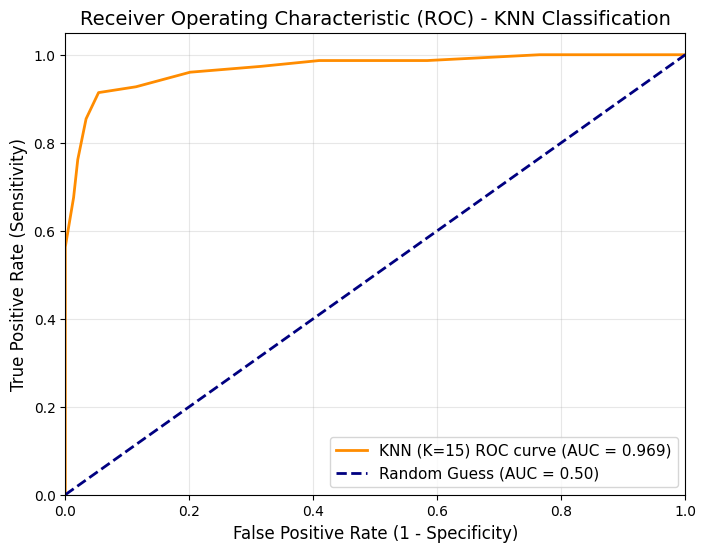

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_curve, roc_auc_score

# -------------------------------------------------------------------
# 1. Generate Synthetic Data & Split
# -------------------------------------------------------------------
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=5,
    n_classes=2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# -------------------------------------------------------------------
# 2. Feature Scaling (Essential for distance calculations in KNN)
# -------------------------------------------------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -------------------------------------------------------------------
# 3. Train KNN Classifier & Extract Probabilities
# -------------------------------------------------------------------
K = 15
knn = KNeighborsClassifier(n_neighbors=K)
knn.fit(X_train_scaled, y_train)

# Predict probabilities for the positive class (column index 1)
# DO NOT use knn.predict(X_test_scaled) here!
y_probs = knn.predict_proba(X_test_scaled)[:, 1]

# -------------------------------------------------------------------
# 4. Compute ROC Curve Metrics and AUC Score
# -------------------------------------------------------------------
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
auc_score = roc_auc_score(y_test, y_probs)

print(f"ROC-AUC Score for K={K}: {auc_score:.4f}")

# -------------------------------------------------------------------
# 5. Plot ROC Curve
# -------------------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'KNN (K={K}) ROC curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) - KNN Classification', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()